# Chapter 6: Advanced Logistic Regression and Extensions

*Summary notebook untuk **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025) — Chapter 6.*

Bab ini membahas pengembangan **logistic regression** untuk masalah klasifikasi yang lebih beragam. Selain klasifikasi biner, kita akan mempelajari klasifikasi multikelas (*multiclass*), regularisasi, klasifikasi multilabel, serta metrik untuk mengevaluasi model.

Notebook ini menggunakan contoh yang dapat dijalankan langsung dan penjelasan berbahasa Indonesia. Contoh kode disusun sebagai bahan belajar berdasarkan topik bab, bukan salinan kode buku secara verbatim.

**Topik utama:**
1. Overview of logistic regression
2. Multiclass classification techniques
3. Regularization in logistic regression
4. Multilabel classification concepts
5. Model evaluation metrics
6. Implementasi dan praktik penggunaan di scikit-learn

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

import sklearn
print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"pandas version: {pd.__version__}")

scikit-learn version: 1.8.0
NumPy version: 2.3.5
pandas version: 2.2.3


> **Catatan versi.** API scikit-learn dapat berubah antarversi. Contoh di notebook ini menghindari penggunaan parameter `multi_class` yang sudah deprecated pada versi baru. Pastikan versi pustaka yang digunakan sesuai dengan lingkungan Python Anda.

## 1. Overview of Logistic Regression

### Ringkasan

**Logistic regression** adalah algoritma supervised learning yang umum digunakan untuk klasifikasi. Berbeda dari linear regression yang memprediksi nilai kontinu, logistic regression memperkirakan probabilitas suatu sampel termasuk ke kelas tertentu.

Untuk klasifikasi biner, probabilitas kelas positif dapat ditulis menggunakan fungsi sigmoid:

$$
P(Y=1\\mid X)=\\frac{1}{1+e^{-z}}, \\qquad
z=\\beta_0+\\beta_1X_1+\\cdots+\\beta_nX_n
$$

Nilai probabilitas berada pada rentang 0 sampai 1. Dengan threshold 0,5 sebagai aturan sederhana, probabilitas di atas atau sama dengan 0,5 diprediksi sebagai kelas positif, sedangkan nilai di bawahnya sebagai kelas negatif. Threshold ini dapat disesuaikan dengan kebutuhan masalah.

Pada contoh berikut, kita menggunakan **Breast Cancer Wisconsin dataset** yang tersedia di scikit-learn. Dataset ini memiliki dua kelas dan fitur numerik yang berasal dari pengukuran citra sel.

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report
)

cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

print("Ukuran fitur:", X.shape)
print("Nama kelas:", cancer.target_names)
print("Jumlah sampel per kelas:", dict(zip(*np.unique(y, return_counts=True))))

Ukuran fitur: (569, 30)
Nama kelas: ['malignant' 'benign']
Jumlah sampel per kelas: {np.int64(0): np.int64(212), np.int64(1): np.int64(357)}


### Membagi data dan melatih model

Data dibagi menjadi data latih dan data uji. Parameter `stratify=y` menjaga proporsi kelas agar relatif sama pada kedua bagian. Standardisasi ditempatkan di dalam pipeline sehingga nilai rata-rata dan standar deviasi dipelajari dari data latih saja.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=2024, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=2024)
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

Accuracy: 0.971

Classification report:
              precision    recall  f1-score   support

   malignant       0.97      0.95      0.96        64
      benign       0.97      0.98      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171



**Membaca hasil.** *Accuracy* menunjukkan proporsi prediksi yang benar secara keseluruhan. Sementara itu, `classification_report` menampilkan **precision**, **recall**, **F1-score**, dan jumlah sampel (*support*) untuk setiap kelas. Dalam konteks medis, jangan hanya mengandalkan accuracy: recall untuk kelas yang menjadi perhatian dapat lebih penting karena berkaitan dengan banyaknya kasus positif yang berhasil ditemukan. Perhatikan bahwa pada dataset scikit-learn ini, label `1` adalah **benign** dan label `0` adalah **malignant**; karena itu, contoh ROC AUC di bawah memakai `benign` sebagai kelas positif. Jika fokus analisis adalah deteksi malignant, tentukan ulang label positif dan interpretasikan metrik sesuai kebutuhan.

### Melihat probabilitas prediksi

Metode `predict_proba()` mengembalikan probabilitas untuk setiap kelas. Urutan kolomnya mengikuti `model.classes_` pada estimator klasifikasi terakhir.

In [4]:
classifier = model[-1]
print("Urutan kelas:", classifier.classes_)
print("Lima probabilitas pertama:")
print(np.round(model.predict_proba(X_test[:5]), 3))

Urutan kelas: [0 1]
Lima probabilitas pertama:
[[0.001 0.999]
 [0.    1.   ]
 [0.436 0.564]
 [1.    0.   ]
 [1.    0.   ]]


## 2. Multiclass Classification Techniques

### Ringkasan

Masalah **multiclass classification** memiliki lebih dari dua kelas. Dua pendekatan yang umum dibahas adalah:

- **One-vs-Rest (OvR):** melatih satu classifier biner untuk setiap kelas, dengan kelas tersebut sebagai positif dan kelas lain sebagai negatif.
- **Multinomial logistic regression:** memodelkan probabilitas seluruh kelas secara bersamaan, sering disebut juga *softmax regression*.

Untuk demonstrasi, kita menggunakan dataset Iris yang memiliki tiga kelas bunga. Pada versi scikit-learn modern, `LogisticRegression` dengan solver `lbfgs` secara otomatis mendukung pendekatan multinomial untuk masalah multikelas. Untuk OvR, kita membungkus estimator biner dengan `OneVsRestClassifier`.

In [5]:
from sklearn.datasets import load_iris
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X_iris, y_iris = iris.data, iris.target

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_iris, y_iris, test_size=0.30, random_state=2024, stratify=y_iris
)

ovr_model = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(LogisticRegression(solver="liblinear", max_iter=3000))
)
multi_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="lbfgs", max_iter=3000)
)

ovr_model.fit(X_train_i, y_train_i)
multi_model.fit(X_train_i, y_train_i)

pred_ovr = ovr_model.predict(X_test_i)
pred_multi = multi_model.predict(X_test_i)

print(f"Accuracy OvR: {accuracy_score(y_test_i, pred_ovr):.3f}")
print(f"Accuracy multinomial: {accuracy_score(y_test_i, pred_multi):.3f}")

Accuracy OvR: 0.933
Accuracy multinomial: 0.956


### Membandingkan laporan klasifikasi

Kedua pendekatan dapat menghasilkan skor yang sama atau berbeda. Perbedaan kecil tidak otomatis berarti satu pendekatan selalu lebih baik; hasil bergantung pada dataset, pembagian data, solver, regularisasi, dan metrik yang diprioritaskan.

In [6]:
print("=== One-vs-Rest ===")
print(classification_report(y_test_i, pred_ovr, target_names=iris.target_names))

print("=== Multinomial Logistic Regression ===")
print(classification_report(y_test_i, pred_multi, target_names=iris.target_names))

=== One-vs-Rest ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.93      0.87      0.90        15
   virginica       0.88      0.93      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45

=== Multinomial Logistic Regression ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.93      0.93      0.93        15
   virginica       0.93      0.93      0.93        15

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



**Hal yang perlu diperhatikan:**

- **Pemilihan solver:** `liblinear` dapat digunakan untuk model biner yang dibungkus dalam OvR; `lbfgs` merupakan pilihan umum untuk multinomial.
- **Skala fitur:** standardisasi sering membantu model linear ketika rentang fitur berbeda.
- **Evaluasi per kelas:** accuracy saja dapat menyembunyikan kinerja buruk pada kelas tertentu, sehingga periksa precision, recall, dan F1-score.

## 3. Regularization in Logistic Regression

### Ringkasan

**Regularisasi** menambahkan penalti terhadap besarnya koefisien model untuk membantu mengurangi overfitting. Pada logistic regression, dua jenis yang umum adalah:

- **L2 (Ridge):** cenderung mengecilkan koefisien, tetapi biasanya tidak membuat banyak koefisien tepat menjadi nol.
- **L1 (Lasso):** dapat membuat sebagian koefisien menjadi nol, sehingga model dapat menjadi lebih jarang (*sparse*).

Pada `LogisticRegression`, parameter `C` adalah kebalikan dari kekuatan regularisasi: **nilai `C` yang lebih kecil berarti regularisasi lebih kuat**, sedangkan nilai `C` yang lebih besar berarti regularisasi lebih lemah.

In [7]:
from sklearn.metrics import f1_score

regularization_results = []
for penalty, solver in [("l2", "lbfgs"), ("l1", "liblinear")]:
    for C in [0.01, 0.1, 1.0, 10.0]:
        reg_model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                penalty=penalty, C=C, solver=solver,
                max_iter=5000, random_state=2024
            )
        )
        reg_model.fit(X_train, y_train)
        pred = reg_model.predict(X_test)
        regularization_results.append({
            "Penalty": penalty.upper(),
            "C": C,
            "Accuracy": accuracy_score(y_test, pred),
            "F1 (macro)": f1_score(y_test, pred, average="macro")
        })

reg_df = pd.DataFrame(regularization_results)
reg_df.sort_values(["Penalty", "C"])

,Penalty,C,Accuracy,F1 (macro)
4,L1,0.01,0.918129,0.914962
5,L1,0.10,0.964912,0.962772
6,L1,1.00,0.964912,0.962544
7,L1,10.00,0.953216,0.950058
0,L2,0.01,0.959064,0.955237
1,L2,0.10,0.970760,0.968479
2,L2,1.00,0.970760,0.968687
3,L2,10.00,0.970760,0.968479


### Membaca perbandingan regularisasi

Tabel menunjukkan hasil untuk kombinasi jenis penalti dan nilai `C`. Tidak ada satu nilai yang selalu paling baik pada semua dataset. Untuk memilih parameter dengan lebih andal, gunakan cross-validation pada data latih dan pertahankan data uji untuk evaluasi akhir.

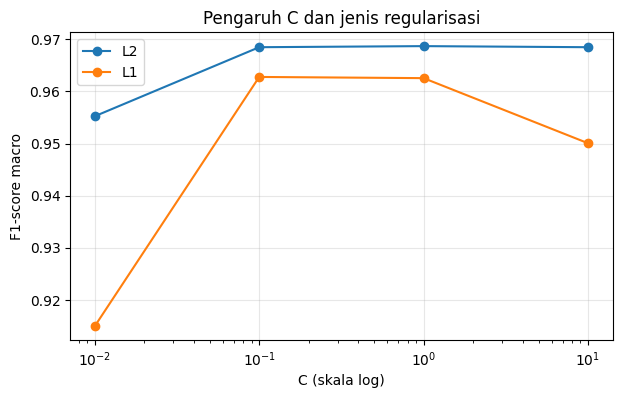

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
for penalty in reg_df["Penalty"].unique():
    subset = reg_df[reg_df["Penalty"] == penalty]
    ax.plot(subset["C"], subset["F1 (macro)"], marker="o", label=f"L{1 if penalty == 'L1' else 2}")
ax.set_xscale("log")
ax.set_xlabel("C (skala log)")
ax.set_ylabel("F1-score macro")
ax.set_title("Pengaruh C dan jenis regularisasi")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

### Mencari parameter dengan cross-validation

`GridSearchCV` menguji beberapa kombinasi parameter melalui cross-validation. Di sini kita memilih `C` dan `penalty`, sementara pipeline memastikan standardisasi dilakukan di dalam setiap fold dan mengurangi risiko *data leakage*.

In [9]:
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=2024)
)
param_grid = {
    "logisticregression__C": [0.01, 0.1, 1.0, 10.0],
    "logisticregression__penalty": ["l1", "l2"],
    "logisticregression__solver": ["liblinear"]
}
search = GridSearchCV(
    pipe, param_grid=param_grid, cv=5, scoring="f1_macro", n_jobs=-1
)
search.fit(X_train, y_train)

print("Parameter terbaik:", search.best_params_)
print(f"Rata-rata F1 macro CV terbaik: {search.best_score_:.3f}")
print(f"F1 macro pada data uji: {f1_score(y_test, search.predict(X_test), average='macro'):.3f}")

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Parameter terbaik: {'logisticregression__C': 1.0, 'logisticregression__penalty': 'l2', 'logisticregression__solver': 'liblinear'}
Rata-rata F1 macro CV terbaik: 0.981
F1 macro pada data uji: 0.969


## 4. Multilabel Classification Concepts

### Ringkasan

Dalam **multiclass classification**, satu sampel biasanya hanya memiliki satu kelas dari beberapa pilihan. Sebaliknya, pada **multilabel classification**, satu sampel dapat memiliki beberapa label sekaligus. Contohnya, satu artikel dapat diberi label “teknologi” dan “bisnis” secara bersamaan.

Salah satu pendekatan yang dapat digunakan adalah `OneVsRestClassifier` dengan target berbentuk matriks indikator: setiap kolom menunjukkan apakah sebuah label berlaku untuk suatu sampel.

In [10]:
from sklearn.datasets import make_multilabel_classification
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import hamming_loss, f1_score

X_ml, y_ml = make_multilabel_classification(
    n_samples=800, n_features=20, n_classes=4,
    n_labels=2, random_state=2024
)

X_train_ml, X_test_ml, y_train_ml, y_test_ml = train_test_split(
    X_ml, y_ml, test_size=0.30, random_state=2024
)

ml_model = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(LogisticRegression(max_iter=3000))
)
ml_model.fit(X_train_ml, y_train_ml)
pred_ml = ml_model.predict(X_test_ml)

print("Bentuk target:", y_ml.shape)
print(f"F1 micro: {f1_score(y_test_ml, pred_ml, average='micro'):.3f}")
print(f"F1 macro: {f1_score(y_test_ml, pred_ml, average='macro'):.3f}")
print(f"Hamming loss: {hamming_loss(y_test_ml, pred_ml):.3f}")

Bentuk target: (800, 4)
F1 micro: 0.752
F1 macro: 0.681
Hamming loss: 0.206


**Memahami metrik multilabel:**

- **F1 micro** menggabungkan keputusan untuk semua label sebelum menghitung skor, sehingga label dengan jumlah kasus lebih banyak memiliki pengaruh lebih besar.
- **F1 macro** menghitung F1 untuk setiap label lalu mengambil rata-ratanya, sehingga setiap label memiliki bobot yang sama.
- **Hamming loss** menghitung proporsi pasangan sampel-label yang salah diprediksi. Nilai lebih kecil berarti lebih baik.

Dalam kasus nyata, tentukan apakah kesalahan *false positive* atau *false negative* lebih mahal sebelum memilih threshold dan metrik.

## 5. Model Evaluation Metrics

### Ringkasan

Metrik evaluasi memberikan sudut pandang berbeda terhadap performa model:

| Metrik | Makna singkat |
|:--|:--|
| Accuracy | Proporsi seluruh prediksi yang benar |
| Precision | Dari semua prediksi positif, proporsi yang benar-benar positif |
| Recall | Dari semua kasus positif sebenarnya, proporsi yang berhasil ditemukan |
| F1-score | Rata-rata harmonik precision dan recall |
| Confusion matrix | Jumlah prediksi benar dan salah untuk setiap pasangan kelas |
| ROC AUC | Kemampuan model mengurutkan sampel positif di atas sampel negatif pada berbagai threshold |

Untuk klasifikasi biner, confusion matrix pada scikit-learn disusun dengan baris sebagai kelas sebenarnya dan kolom sebagai kelas prediksi.

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score

final_model = search.best_estimator_
final_pred = final_model.predict(X_test)
final_prob = final_model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, final_pred)
print("Confusion matrix:")
print(cm)
print(f"ROC AUC: {roc_auc_score(y_test, final_prob):.3f}")

Confusion matrix:
[[ 61   3]
 [  2 105]]
ROC AUC: 0.995


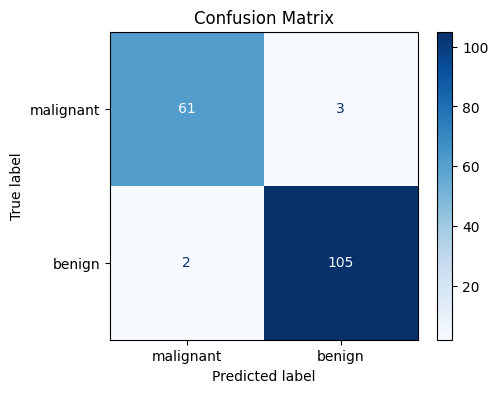

In [12]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, final_pred,
    display_labels=cancer.target_names,
    cmap="Blues",
    ax=ax
)
ax.set_title("Confusion Matrix")
plt.show()

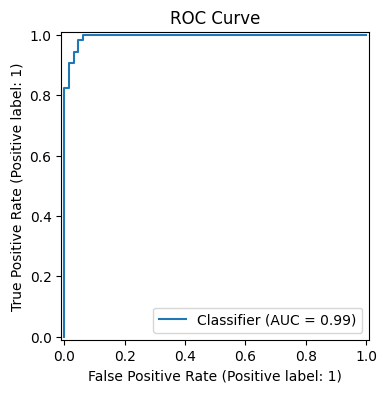

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
RocCurveDisplay.from_predictions(y_test, final_prob, ax=ax)
ax.set_title("ROC Curve")
plt.show()

### Interpretasi metrik

- Pada confusion matrix, nilai diagonal menunjukkan prediksi yang benar; nilai di luar diagonal menunjukkan kesalahan klasifikasi.
- Precision tinggi berarti lebih sedikit prediksi positif yang keliru.
- Recall tinggi berarti lebih banyak kasus positif sebenarnya yang ditemukan.
- ROC AUC mendekati 1 menunjukkan pemisahan kelas yang baik berdasarkan skor probabilitas; nilai sekitar 0,5 menunjukkan performa yang setara dengan pengurutan acak.

Metrik yang diprioritaskan harus mengikuti tujuan aplikasi. Misalnya, skrining medis dapat lebih mementingkan recall, sedangkan sistem yang mahal ketika menghasilkan alarm palsu mungkin perlu menekankan precision.

## 6. Praktik Penggunaan dan Best Practices

### Alur kerja yang disarankan

1. Tentukan apakah target merupakan klasifikasi biner, multiclass, atau multilabel.
2. Pisahkan data latih dan data uji sebelum melakukan pemodelan.
3. Gunakan pipeline untuk menggabungkan preprocessing dan model.
4. Pilih metrik yang sesuai dengan dampak kesalahan prediksi.
5. Gunakan cross-validation untuk pemilihan hyperparameter.
6. Evaluasi model terpilih pada data uji yang tidak digunakan saat tuning.
7. Periksa warning konvergensi; tingkatkan `max_iter` atau tinjau preprocessing bila diperlukan.

### Kesimpulan

Logistic regression merupakan model klasifikasi yang relatif sederhana dan mudah diinterpretasikan. Model ini dapat diperluas untuk menangani beberapa kelas maupun beberapa label. Regularisasi membantu mengendalikan kompleksitas model, sementara evaluasi yang tepat membantu kita memahami jenis kesalahan yang dibuat model. Jangan memilih model hanya berdasarkan accuracy; pertimbangkan juga precision, recall, F1-score, ROC AUC, serta kebutuhan aplikasi.

## Referensi dan catatan

- John Sukup, *scikit-learn Cookbook, Third Edition*, Packt, 2025 — Chapter 6: **Advanced Logistic Regression and Extensions**.
- Dokumentasi scikit-learn: `LogisticRegression`, `OneVsRestClassifier`, `GridSearchCV`, dan `sklearn.metrics`.

Contoh notebook ini merupakan ringkasan belajar dalam bahasa Indonesia dengan implementasi contoh yang disusun ulang. Hasil numerik dapat berbeda jika versi pustaka atau lingkungan eksekusi berbeda.